In [12]:
import sys
sys.path.append("..")

In [13]:
import torch
import torch.nn.functional as F
from src.vgg import VGGFeatures
from src.image_utils import load_image
from src.losses import gram_matrix, style_grams, style_loss, content_loss

In [14]:
device = "cuda"
style = load_image("../data/style/starry_night.jpg", 384, device)
content = load_image("../data/content/Abyssinian_24.jpg", 384, device)

In [15]:
extractor = VGGFeatures().to(device)
layers = ["conv1_1", "conv2_1", "conv3_1", "conv4_1", "conv5_1"]

In [16]:
with torch.no_grad():
    content_target = extractor(content)["conv4_2"]
    style_feats = extractor(style)
    target_grams = {k: v.detach() for k, v in style_grams(style_feats).items()}

In [21]:
image = content.clone().requires_grad_(True)
content_weight = 1
style_weight = 1e4

In [22]:
optimiser = torch.optim.Adam([image], lr=0.02)

In [23]:
for i in range(501):
    features = extractor(image)
    c = content_loss(features["conv4_2"], content_target)
    s = style_loss(features, target_grams)
    total = content_weight * c + style_weight * s
    optimiser.zero_grad()
    total.backward()
    optimiser.step()

    with torch.no_grad():
        image.clamp_(0,1)

    if i % 100 == 0:
        print(f"Iteration {i}: c_loss = {c.item():.4f}")
        print(f"Iteration {i}: s_loss = {s.item():.4f}")
        print(f"Iteration {i}: total_loss = {total.item():.4f}")

Iteration 0: c_loss = 0.0000
Iteration 0: s_loss = 0.0483
Iteration 0: total_loss = 483.1177
Iteration 100: c_loss = 14.9823
Iteration 100: s_loss = 0.0014
Iteration 100: total_loss = 29.3643
Iteration 200: c_loss = 12.9581
Iteration 200: s_loss = 0.0009
Iteration 200: total_loss = 22.0489
Iteration 300: c_loss = 11.1612
Iteration 300: s_loss = 0.0008
Iteration 300: total_loss = 19.3852
Iteration 400: c_loss = 10.2887
Iteration 400: s_loss = 0.0008
Iteration 400: total_loss = 17.9981
Iteration 500: c_loss = 10.0611
Iteration 500: s_loss = 0.0007
Iteration 500: total_loss = 16.8153


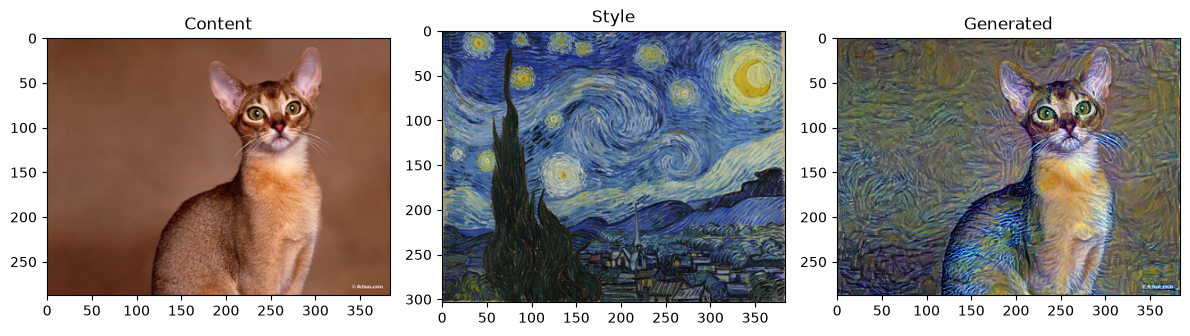

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(12, 6))

ax[0].set_title("Content")
ax[0].imshow(content.detach().cpu().squeeze(0).permute(1,2,0).numpy())
ax[1].set_title("Style")
ax[1].imshow(style.detach().cpu().squeeze(0).permute(1,2,0).numpy())
ax[2].set_title("Generated")
ax[2].imshow(image.detach().cpu().squeeze(0).permute(1,2,0).numpy())
fig.tight_layout()
fig.savefig("../outputs/stylised_cat_starry.jpg")

In [24]:
from src.image_utils import save_image
save_image(image, "../outputs/compare_cat_starry.jpg")